In [1]:
# Part A — Load the Step 3 dataset
# Cell 1: Import libraries and load the dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Load the Step 3 dataset
file_path = Path(
    "nassau-candy-factory-optimization/data/Nassau_Candy_Feature_Engineered_Step3.csv"
)

if not file_path.exists():
    raise FileNotFoundError(
        f"Dataset not found: {file_path}\n"
        "Check the location and filename of your Step 3 CSV."
    )

df = pd.read_csv(file_path)

print("Step 4: Predictive Modeling")
print("-" * 50)
print("Dataset shape:", df.shape)

display(df.head())


Step 4: Predictive Modeling
--------------------------------------------------
Dataset shape: (10194, 25)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Units,Gross Profit,Cost,Shipping Lead Time Days,Financial Reconciliation Difference,Order Year,Order Month,Order Quarter,Order Day of Week,Order Day of Month
0,1,US-2021-103800-CHO-MIL-31000,2024-03-01,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,...,2,4.22,2.28,909.0,8.881784e-16,2024.0,3.0,1.0,4.0,1.0
1,2,US-2021-112326-CHO-TRI-54000,2024-04-01,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,2,4.90,2.60,909.0,0.000000e+00,2024.0,4.0,2.0,0.0,1.0
2,3,US-2021-112326-CHO-NUT-13000,2024-04-01,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,3,7.47,3.00,909.0,8.881784e-16,2024.0,4.0,2.0,0.0,1.0
3,4,US-2021-112326-CHO-SCR-58000,2024-04-01,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,3,7.50,3.30,909.0,8.881784e-16,2024.0,4.0,2.0,0.0,1.0
4,5,US-2021-141817-CHO-TRI-54000,2024-05-01,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,3,7.35,3.90,912.0,0.000000e+00,2024.0,5.0,2.0,2.0,1.0


In [2]:
#Cell 2: Verify the modeling columns
target_column = "Shipping Lead Time Days"

feature_columns = [
    "Region",
    "Ship Mode",
    "Division",
    "Product ID",
    "Units",
    "Order Year",
    "Order Month",
    "Order Quarter",
    "Order Day of Week",
    "Order Day of Month"
]

required_columns = feature_columns + [target_column]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required modeling columns are available.")

All required modeling columns are available.


In [3]:
# Part B — Prepare the training data

# Cell 3: Validate the target and sort by order date
# Convert dates to datetime
# Use dayfirst=True only if the source dates are DD-MM-YYYY.
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    errors="coerce",
    dayfirst=True
)

# Ensure the target is numeric
df[target_column] = pd.to_numeric(
    df[target_column],
    errors="coerce"
)

# Keep rows with valid order dates and target values
model_data = df.dropna(
    subset=["Order Date", target_column]
).copy()

# Remove negative targets only after confirming they are invalid.
# Here we exclude them from model training and report the count.
negative_target_count = (
    model_data[target_column] < 0
).sum()

print("Negative target values:", negative_target_count)

model_data = model_data[
    model_data[target_column] >= 0
].copy()

# Sort chronologically
model_data = model_data.sort_values(
    "Order Date"
).reset_index(drop=True)

print("Rows available for modeling:", len(model_data))
print(
    "Order date range:",
    model_data["Order Date"].min(),
    "to",
    model_data["Order Date"].max()
)

Negative target values: 0
Rows available for modeling: 4130
Order date range: 2024-01-02 00:00:00 to 2025-12-12 00:00:00


In [4]:
# Cell 4: Split into training and testing sets

# We will use the earliest 80% of observations for training and the latest 20% for testing.

split_index = int(len(model_data) * 0.80)

if split_index == 0 or split_index >= len(model_data):
    raise ValueError(
        "Not enough valid rows to create a training/test split."
    )

train_data = model_data.iloc[:split_index].copy()
test_data = model_data.iloc[split_index:].copy()

X_train = train_data[feature_columns].copy()
y_train = train_data[target_column].copy()

X_test = test_data[feature_columns].copy()
y_test = test_data[target_column].copy()

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print(
    "Training period:",
    train_data["Order Date"].min(),
    "to",
    train_data["Order Date"].max()
)

print(
    "Testing period:",
    test_data["Order Date"].min(),
    "to",
    test_data["Order Date"].max()
)


Training rows: 3304
Testing rows: 826
Training period: 2024-01-02 00:00:00 to 2025-10-12 00:00:00
Testing period: 2025-10-12 00:00:00 to 2025-12-12 00:00:00


In [5]:
# Cell 5: Import machine-learning tools
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import sklearn

print("scikit-learn version:", sklearn.__version__)


scikit-learn version: 1.9.0


In [6]:
#Cell 6: Define categorical and numerical columns
categorical_features = [
    "Region",
    "Ship Mode",
    "Division",
    "Product ID"
]

numerical_features = [
    "Units",
    "Order Year",
    "Order Month",
    "Order Quarter",
    "Order Day of Week",
    "Order Day of Month"
]

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)


Categorical features: ['Region', 'Ship Mode', 'Division', 'Product ID']
Numerical features: ['Units', 'Order Year', 'Order Month', 'Order Quarter', 'Order Day of Week', 'Order Day of Month']


In [7]:
# Cell 7: Create preprocessing pipelines
# Handle missing numerical values and standardize them
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Handle missing categories and encode text
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [8]:
# Part D — Train three predictive models

#Cell 8: Define the models
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

print("Models defined:")
for model_name in models:
    print("-", model_name)





Models defined:
- Linear Regression
- Random Forest
- Gradient Boosting


In [9]:
# Cell 9: Train and evaluate all three models
results = []
trained_models = {}
predictions = {}

for model_name, estimator in models.items():

    # Combine preprocessing and model
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", estimator)
        ]
    )

    # Train using the training set
    pipeline.fit(X_train, y_train)

    # Predict on unseen test data
    y_pred = pipeline.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    r2 = r2_score(y_test, y_pred)

    # Store outputs
    trained_models[model_name] = pipeline
    predictions[model_name] = y_pred

    results.append({
        "Model": model_name,
        "MAE (days)": mae,
        "RMSE (days)": rmse,
        "R²": r2
    })

    print(f"\nCompleted: {model_name}")
    print(f"MAE:  {mae:.3f} days")
    print(f"RMSE: {rmse:.3f} days")
    print(f"R²:   {r2:.3f}")



Completed: Linear Regression
MAE:  180.357 days
RMSE: 183.053 days
R²:   -0.015

Completed: Random Forest
MAE:  177.243 days
RMSE: 186.034 days
R²:   -0.048

Completed: Gradient Boosting
MAE:  176.327 days
RMSE: 182.495 days
R²:   -0.009


In [10]:
# Part E — Compare model performance
# Cell 10: Create the comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="MAE (days)",
    ascending=True
).reset_index(drop=True)

display(
    results_df.style.format({
        "MAE (days)": "{:.3f}",
        "RMSE (days)": "{:.3f}",
        "R²": "{:.3f}"
    })
)

#MAE	Average absolute prediction error	Lower
#RMSE	Penalizes larger prediction errors more strongly	Lower
#R²	Compares model predictions with a baseline based on the target mean	Higher, with caveats


,Model,MAE (days),RMSE (days),R²
0,Gradient Boosting,176.327,182.495,-0.009
1,Random Forest,177.243,186.034,-0.048
2,Linear Regression,180.357,183.053,-0.015


Lowest-MAE model: Gradient Boosting


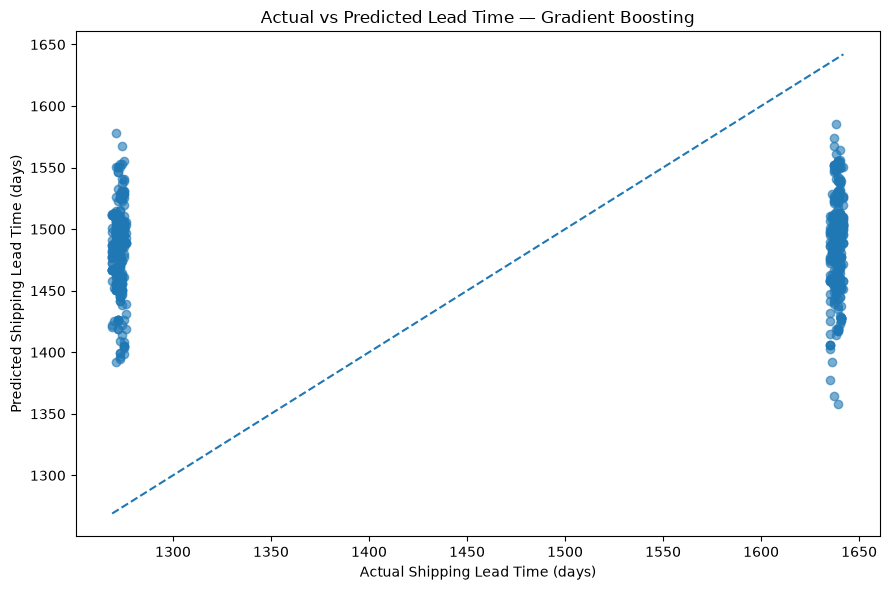

In [11]:
#Part F — Visualize predicted versus actual lead times
#Cell 11: Plot the best model's predictions

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

best_predictions = predictions[best_model_name]

print("Lowest-MAE model:", best_model_name)

plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.6
)

min_value = min(
    y_test.min(),
    best_predictions.min()
)

max_value = max(
    y_test.max(),
    best_predictions.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Shipping Lead Time (days)")
plt.ylabel("Predicted Shipping Lead Time (days)")
plt.title(f"Actual vs Predicted Lead Time — {best_model_name}")

plt.tight_layout()
plt.show()

#Interpretition : 

#Points close to the diagonal line indicate predictions close to actual values.
#Points above the line represent overpredictions.
#Points below the line represent underpredictions.
#Large deviations indicate orders for which the model performs poorly.

In [12]:
# Part G — Inspect prediction errors
# Cell 12: Create an error-analysis table
prediction_results = test_data[
    [
        "Order Date",
        "Region",
        "Ship Mode",
        "Division",
        "Product ID",
        "Units",
        target_column
    ]
].copy()

prediction_results["Predicted Lead Time Days"] = (
    best_predictions
)

prediction_results["Prediction Error Days"] = (
    prediction_results["Predicted Lead Time Days"]
    - prediction_results[target_column]
)

prediction_results["Absolute Error Days"] = (
    prediction_results["Prediction Error Days"].abs()
)

display(
    prediction_results.sort_values(
        by="Absolute Error Days",
        ascending=False
    ).head(20)
)

# This table identifies orders with the largest prediction errors.


,Order Date,Region,Ship Mode,Division,Product ID,Units,Shipping Lead Time Days,Predicted Lead Time Days,Prediction Error Days,Absolute Error Days
3789,2025-12-02,Interior,Second Class,Other,OTH-LIC-15000,10,1271.0,1577.844437,306.844437,306.844437
3609,2025-11-11,Pacific,Standard Class,Chocolate,CHO-FUD-51000,11,1274.0,1567.364793,293.364793,293.364793
3311,2025-10-12,Interior,Standard Class,Chocolate,CHO-MIL-31000,14,1639.0,1358.144878,-280.855122,280.855122
3776,2025-12-02,Pacific,Standard Class,Chocolate,CHO-TRI-54000,7,1275.0,1555.316319,280.316319,280.316319
3815,2025-12-03,Pacific,Standard Class,Chocolate,CHO-TRI-54000,8,1273.0,1553.212417,280.212417,280.212417
3388,2025-11-03,Pacific,First Class,Chocolate,CHO-SCR-58000,7,1271.0,1550.372325,279.372325,279.372325
3384,2025-11-03,Pacific,Standard Class,Chocolate,CHO-NUT-13000,7,1274.0,1553.212417,279.212417,279.212417
3386,2025-11-03,Pacific,First Class,Chocolate,CHO-TRI-54000,7,1272.0,1550.372325,278.372325,278.372325
3831,2025-12-03,Pacific,First Class,Chocolate,CHO-SCR-58000,6,1272.0,1550.372325,278.372325,278.372325
3727,2025-12-01,Pacific,Standard Class,Chocolate,CHO-TRI-54000,8,1273.0,1550.614933,277.614933,277.614933


In [13]:
# Part H — Save the selected model and results

# Cell 13: Save the model

import joblib

model_dir = Path("nassau-candy-factory-optimization/step4_outputs")
model_dir.mkdir(parents=True, exist_ok=True)

# Fixed: Added quotes around the filename path
model_file = model_dir / "best_shipping_lead_time_model.joblib"

joblib.dump(best_model, model_file)
print("Model saved successfully:")
print(model_file)

Model saved successfully:
nassau-candy-factory-optimization\step4_outputs\best_shipping_lead_time_model.joblib


In [14]:
# Cell 14: Save the evaluation results
results_dir = Path(
   "nassau-candy-factory-optimization\data\step4_outputs"
)

results_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Save the comparison of all three models
results_df.to_csv(
    results_dir / "model_comparison.csv",
    index=False
)

# Save the selected model's test predictions and errors
prediction_results.to_csv(
    results_dir / "best_model_test_predictions.csv",
    index=False
)

print("Model evaluation outputs saved to:")
print(results_dir)


Model evaluation outputs saved to:
nassau-candy-factory-optimization\data\step4_outputs


In [15]:
# Cell 15: Verify the saved model
loaded_model = joblib.load(model_file)

# Predict a few rows using the saved model
sample_predictions = loaded_model.predict(
    X_test.head(5)
)

print("Saved model loaded successfully.")
print("Sample predictions:", sample_predictions)

Saved model loaded successfully.
Sample predictions: [1441.0931247  1449.74031864 1467.17813559 1463.67653682 1364.78590684]
